In [1]:
#importing all the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
import time
from sklearn.metrics import classification_report, roc_auc_score, RocCurveDisplay

In [2]:
df = pd.read_csv("Amazon_Unlocked_Mobile.csv") #The csv

In [3]:
df.head() #Our data

,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0


In [4]:
#Renaming the columns for easier use
df = df.rename(columns={'Product Name': 'product_name'})
df = df.rename(columns={'Brand Name': 'brand_name'})
df = df.rename(columns={'Rating': 'rating'})
df = df.rename(columns={'Reviews': 'reviews'})
df = df.rename(columns={'Price': 'price'})
df = df.rename(columns={'Review Votes': 'review_votes'})

In [5]:
df.info() #Types of our data so we can be sure that everything is on the right form

<class 'pandas.DataFrame'>
RangeIndex: 413840 entries, 0 to 413839
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   product_name  413840 non-null  str    
 1   brand_name    348669 non-null  str    
 2   price         407907 non-null  float64
 3   rating        413840 non-null  int64  
 4   reviews       413770 non-null  str    
 5   review_votes  401544 non-null  float64
dtypes: float64(2), int64(1), str(3)
memory usage: 138.7 MB


In [6]:
df.shape #The shape of our csv

(413840, 6)

In [7]:
df.isnull().sum() #We indeed have null values

product_name        0
brand_name      65171
price            5933
rating              0
reviews            70
review_votes    12296
dtype: int64

In [8]:
df.dropna(subset=['reviews'], inplace=True) #We drop the null values from the reviews column as it's our main text feature

In [9]:
df.isnull().sum() #Clarification

product_name        0
brand_name      65154
price            5930
rating              0
reviews             0
review_votes    12296
dtype: int64

In [10]:
#Number one rule, we should avoid the data leakage. If we had kept the duplicate reviews,there would have been a huge risk, when performing
#the Train-Test Split that the exact same review could end up in both the training set and the test set.

df.drop_duplicates(subset=['reviews', 'rating'], inplace=True)

In [11]:
df.shape # Almost 1/4 were duplicates

(163958, 6)

In [12]:
df = df[df['rating'] != 3] #We do keep everything but 3

In [13]:
df

,product_name,brand_name,price,rating,reviews,review_votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0
...,...,...,...,...,...,...
413824,Samsung Convoy U640 Phone for Verizon Wireless...,Samsung,79.95,4,works great and picks up signal in place my ot...,0.0
413825,Samsung Convoy U640 Phone for Verizon Wireless...,Samsung,79.95,5,"Great phone. Large keys, best flip phone I hav...",0.0
413826,Samsung Convoy U640 Phone for Verizon Wireless...,Samsung,79.95,5,"Pros...Works great, very durable, easy to navi...",0.0
413827,Samsung Convoy U640 Phone for Verizon Wireless...,Samsung,79.95,5,just as described perfect for the price,0.0


In [14]:
len(df[df['rating'] == 3]) #Clarification

0

In [15]:
df['rating'].value_counts() #Counting

rating
5    78498
1    33011
4    26321
2    11513
Name: count, dtype: int64

In [16]:
#Create binary target variable: 1 for positive sentiment (rating > 3), 0 for negative (rating <= 3)

df['positive_rating'] = np.where(df['rating'] > 3,1,0) 

In [17]:
df['positive_rating'].value_counts() #clarification

positive_rating
1    104819
0     44524
Name: count, dtype: int64

In [18]:
df[['reviews', 'rating', 'positive_rating']].head() #clarification

,reviews,rating,positive_rating
0,I feel so LUCKY to have found this used (phone...,5,1
1,"nice phone, nice up grade from my pantach revu...",4,1
2,Very pleased,5,1
3,It works good but it goes slow sometimes but i...,4,1
4,Great phone to replace my lost phone. The only...,4,1


C:\Users\User\AppData\Local\Temp\ipykernel_20896\493647302.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='positive_rating', palette='viridis')


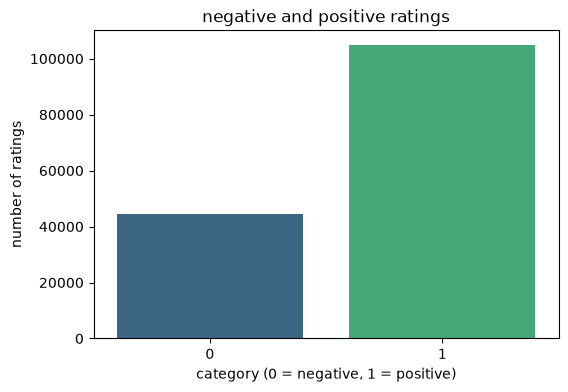

In [19]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='positive_rating', palette='viridis')
plt.title('negative and positive ratings')
plt.xlabel('category (0 = negative, 1 = positive)')
plt.ylabel('number of ratings')
plt.show()

In [20]:
df.head()

,product_name,brand_name,price,rating,reviews,review_votes,positive_rating
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0,1
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0,1
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0,1
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0,1
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0,1


In [21]:
#Defining feature (review text) and target variable (binary sentiment)
X = df['reviews']
y = df['positive_rating']

#Splitting the dataset into 75% training and 25% testing sets (random_state=0 for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (112007,)
X_test shape: (37336,)


In [22]:
#Initialize TF-IDF Vectorizer: ignore rare terms (min_df=5) and capture both unigrams and bigrams
vect = TfidfVectorizer(min_df=5, ngram_range=(1, 2))

#Fit vocabulary ONLY on training data to prevent data leakage, then transform to sparse matrix
X_train_vectorized = vect.fit_transform(X_train)

#Transform test data using the already fitted vocabulary
X_test_vectorized = vect.transform(X_test)

#Output the total number of extracted features (vocabulary size)
print("Vocabulary size (total unigrams and bigrams):", len(vect.get_feature_names_out()))

Vocabulary size (total unigrams and bigrams): 117346


In [23]:
# 1. Train Logistic Regression
print("Training Logistic Regression...")
start_time = time.time()

lr_model = LogisticRegression(max_iter=2000, random_state=0)
lr_model.fit(X_train_vectorized, y_train)

lr_time = time.time() - start_time
print(f"Completed in {lr_time:.2f} seconds.")

# 2. Train XGBoost (Gradient Boosted Trees for non-linear comparison)
print("\nTraining XGBoost (this may take a moment)...")
start_time = time.time()

# Utilize all available CPU cores (n_jobs=-1) to accelerate training
xgb_model = XGBClassifier(eval_metric='logloss', random_state=0, n_jobs=-1)
xgb_model.fit(X_train_vectorized, y_train)

xgb_time = time.time() - start_time
print(f"Completed in {xgb_time:.2f} seconds.")

# 3. Generate predictions on the test set
# Extract both binary class predictions (0 or 1) and probability estimates (for ROC-AUC evaluation)
y_pred_lr = lr_model.predict(X_test_vectorized)
y_prob_lr = lr_model.predict_proba(X_test_vectorized)[:, 1]

y_pred_xgb = xgb_model.predict(X_test_vectorized)
y_prob_xgb = xgb_model.predict_proba(X_test_vectorized)[:, 1]

print("\nAll predictions generated successfully!")

Training Logistic Regression...
Completed in 1.16 seconds.

Training XGBoost (this may take a moment)...
Completed in 80.25 seconds.

All predictions generated successfully!


LOGISTIC REGRESSION EVALUATION
              precision    recall  f1-score   support

           0       0.92      0.87      0.89     11105
           1       0.95      0.97      0.96     26231

    accuracy                           0.94     37336
   macro avg       0.93      0.92      0.93     37336
weighted avg       0.94      0.94      0.94     37336

ROC-AUC Score: 0.9793

XGBOOST EVALUATION
              precision    recall  f1-score   support

           0       0.89      0.82      0.85     11105
           1       0.93      0.96      0.94     26231

    accuracy                           0.92     37336
   macro avg       0.91      0.89      0.90     37336
weighted avg       0.92      0.92      0.92     37336

ROC-AUC Score: 0.9673



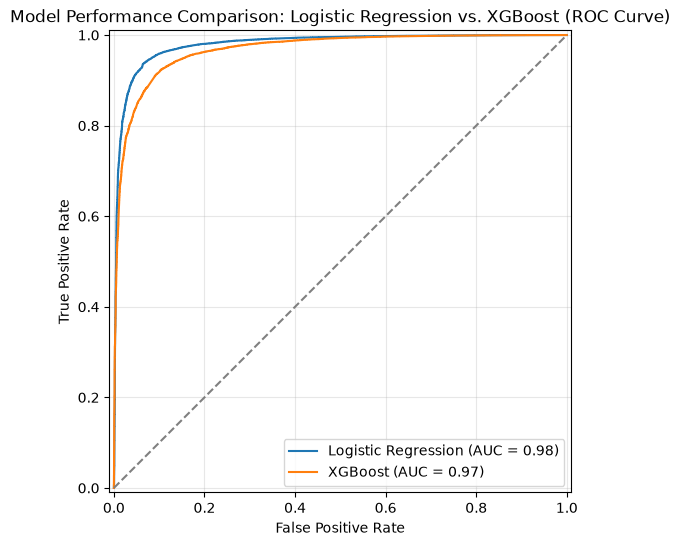

In [24]:
# 1. Print detailed classification metrics (Precision, Recall, F1-Score, ROC-AUC)
print("="*40)
print("LOGISTIC REGRESSION EVALUATION")
print("="*40)
print(classification_report(y_test, y_pred_lr))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_lr):.4f}\n")

print("="*40)
print("XGBOOST EVALUATION")
print("="*40)
print(classification_report(y_test, y_pred_xgb))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_xgb):.4f}\n")

# 2. Plot comparative ROC Curves
fig, ax = plt.subplots(figsize=(8, 6))

# Plot Logistic Regression ROC curve
RocCurveDisplay.from_predictions(
    y_test, y_prob_lr, ax=ax, name="Logistic Regression"
)

# Plot XGBoost ROC curve
RocCurveDisplay.from_predictions(
    y_test, y_prob_xgb, ax=ax, name="XGBoost"
)

# Plot diagonal baseline representing a random classifier (AUC = 0.50)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Classifier')

plt.title("Model Performance Comparison: Logistic Regression vs. XGBoost (ROC Curve)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.grid(alpha=0.3)
plt.show()

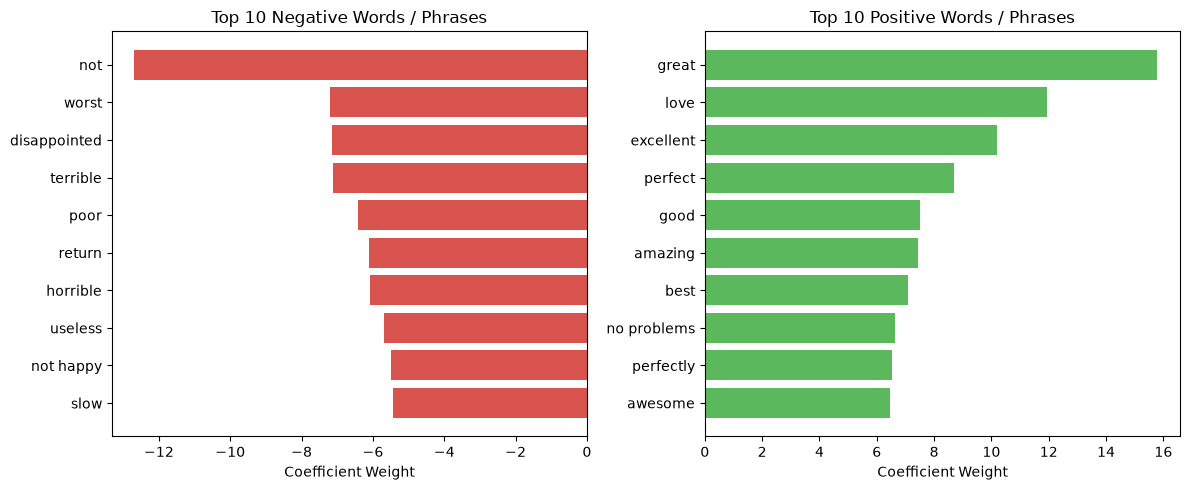

In [25]:
# 1. Extract the vocabulary (unigrams and bigrams) from the TF-IDF vectorizer
feature_names = np.array(vect.get_feature_names_out())

# 2. Sort the Logistic Regression model coefficients in ascending order
sorted_coef_index = lr_model.coef_[0].argsort()

# 3. Isolate the top 10 negative (lowest weights) and top 10 positive (highest weights) features
top_negative = pd.DataFrame({
    'Feature': feature_names[sorted_coef_index[:10]],
    'Coefficient': lr_model.coef_[0][sorted_coef_index[:10]]
})

top_positive = pd.DataFrame({
    'Feature': feature_names[sorted_coef_index[:-11:-1]],
    'Coefficient': lr_model.coef_[0][sorted_coef_index[:-11:-1]]
})

# 4. Visualize Feature Importance (Model Explainability)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot top negative features
axes[0].barh(top_negative['Feature'], top_negative['Coefficient'], color='#d9534f')
axes[0].set_title('Top 10 Negative Words / Phrases')
axes[0].set_xlabel('Coefficient Weight')
axes[0].invert_yaxis()  # Invert y-axis so the strongest negative term appears at the top

# Plot top positive features
axes[1].barh(top_positive['Feature'], top_positive['Coefficient'], color='#5cb85c')
axes[1].set_title('Top 10 Positive Words / Phrases')
axes[1].set_xlabel('Coefficient Weight')
axes[1].invert_yaxis()  # Invert y-axis so the strongest positive term appears at the top

plt.tight_layout()
plt.show()